## Dia 4 — Médias iguais, experiências diferentes

### Situação

Dois postos de atendimento querem comparar seus tempos de espera. Uma comparação baseada apenas nas médias pode esconder uma diferença importante: em um posto, as esperas podem ser mais regulares; no outro, podem variar bastante. Você deve quantificar essa diferença e explicar o resultado.

### Dados disponíveis

O arquivo `filas.csv` contém as colunas `posto` e `minutos`. O posto A tem tempos 8, 9, 10, 11 e 12; o B tem 2, 6, 10, 14 e 18. No primeiro cenário, esses são todos os atendimentos de uma manhã, ou seja, a população finita que você está descrevendo. No segundo cenário, imagine que os mesmos registros sejam apenas uma amostra de atendimentos de muitas manhãs.

### Sua tarefa

1. No cenário da manhã completa, calcule a média, a variância com divisor `n` e o desvio padrão de cada posto. Ao usar uma biblioteca, declare `ddof=0` para essa convenção.
2. Para o posto A, apresente uma tabela com cada tempo, seu desvio em relação à média e o quadrado desse desvio. Use essa tabela para conferir a variância.
3. No cenário amostral, recalcule a variância e o desvio padrão de A com divisor `n-1`, correspondente a `ddof=1`. Explique por que esse cálculo atende a uma finalidade diferente da descrição da manhã completa.
4. Compare os postos e descreva o que a dispersão acrescenta à informação trazida pela média.

### Entrega

Apresente a tabela comparativa dos postos, a memória de cálculo de A e uma explicação dos dois cenários.

### Confira seu avanço

- [ ] A soma dos desvios em relação à média fica aproximadamente igual a zero em cada posto.
- [ ] Informei a variância em minutos quadrados e o desvio padrão em minutos.
- [ ] Declarei o divisor usado e diferenciei descrição da população finita de estimação com uma amostra.

### Interpretação

1. Que diferença na experiência de espera dos usuários não aparece ao olhar apenas a média?
2. Por que a escolha entre `n` e `n-1` precisa considerar a finalidade da análise?

### Leituras de apoio

Fávero e Belfiore, Manual de Análise de Dados, cap. 2; Manual de Análise de Dados em Python (repositório de apoio), cap. 2.


## Minha estratégia

Explique como pretende abordar o problema.

## Resolução

Os arquivos de dados estão nesta pasta. Se necessário, confira o diretório de execução com `Path.cwd()`. Acrescente células conforme precisares.

In [25]:
import pandas as pd


# ■■■ LEITURA DOS DADOS

dados_postos = pd.read_csv('filas.csv')


# ■■■ MEDIDAS POPULACIONAIS PELA FÓRMULA

# ====== Média de cada posto

# ------ A média do grupo é atribuída a cada linha do posto.
dados_postos['media'] = (
    dados_postos
    .groupby('posto')['minutos']
    .transform('mean')
)


# ====== Variância com divisor n

# ------ Calcula o quadrado do desvio em relação à média do posto.
dados_postos['var'] = (
    dados_postos['minutos'] - dados_postos['media']
) ** 2

# ------ A média dos quadrados dos desvios corresponde à variância.
variancia_por_posto = (
    dados_postos
    .groupby('posto')['var']
    .mean()
)


# ====== Desvio padrão

# ------ O desvio padrão é a raiz quadrada da variância.
desvio_por_posto = variancia_por_posto ** 0.5

print('Variância pela fórmula (min²):')
display(variancia_por_posto)

print('Desvio padrão pela fórmula (min):')
display(desvio_por_posto)


# ■■■ MEDIDAS POPULACIONAIS COM PANDAS

# ====== Média, variância e desvio padrão por posto

# ------ ddof é o ajuste aplicado ao divisor: n - ddof.
# ------ ddof=0 utiliza n; ddof=1 utiliza n - 1.
comparacao_populacional = (
    dados_postos
    .groupby('posto')['minutos']
    .agg(
        media='mean',
        variancia=lambda valores: valores.var(ddof=0),
        desvio_padrao=lambda valores: valores.std(ddof=0),
    )
)

display(comparacao_populacional)

Variância pela fórmula (min²):


posto
A     2.0
B    32.0
Name: var, dtype: float64

Desvio padrão pela fórmula (min):


posto
A    1.414214
B    5.656854
Name: var, dtype: float64

,media,variancia,desvio_padrao
posto,,,
A,10.0,2.0,1.414214
B,10.0,32.0,5.656854


In [ ]:
# 2. Para o posto A, apresente uma tabela com cada tempo, seu desvio em relação à média e o quadrado desse desvio. 
# Use essa tabela para conferir a variância.

display(dados_postos)

# ------ Filtra apenas as linhas do posto A
tabela_posto_a = dados_postos[dados_postos['posto'] == 'A'].copy()

# ------- Ajustes em nomeclaturas e cálculo de diff 
tabela_posto_a['diff'] = tabela_posto_a['minutos'] - tabela_posto_a['media']
tabela_posto_a.rename(columns={"var": "diff^2"}, inplace=True)
tabela_posto_a = tabela_posto_a[["posto", "minutos", "media", "diff", "diff^2"]]
display(tabela_posto_a)

# ------ Conferência da variância populacional do posto A (divisor n)
variancia_conferida = tabela_posto_a['diff^2'].sum() / len(tabela_posto_a)
print(f"Variância conferida para o Posto A: {variancia_conferida}")

,posto,minutos,media,var
0,A,8,10.0,4.0
1,A,9,10.0,1.0
2,A,10,10.0,0.0
3,A,11,10.0,1.0
4,A,12,10.0,4.0
5,B,2,10.0,64.0
6,B,6,10.0,16.0
7,B,10,10.0,0.0
8,B,14,10.0,16.0
9,B,18,10.0,64.0


,posto,minutos,media,diff,diff^2
0,A,8,10.0,-2.0,4.0
1,A,9,10.0,-1.0,1.0
2,A,10,10.0,0.0,0.0
3,A,11,10.0,1.0,1.0
4,A,12,10.0,2.0,4.0


Variância conferida para o Posto A: 2.0


In [ ]:
# 3. No cenário amostral, recalcule a variância e o desvio padrão de A com divisor `n-1`, correspondente a `ddof=1`.
#  Explique por que esse cálculo atende a uma finalidade diferente da descrição da manhã completa.

# Quando temos todos os atendimentos da manhã, usamos n para descrever
# a variância daquela manhã.
#
# Se esses atendimentos forem uma amostra de muitas manhãs, usamos n - 1
# para estimar a variância do conjunto maior. Esse ajuste ajuda a corrigir
# a tendência de subestimar a variância ao trabalhar com uma amostra.

# ---- Cálculo da Variância Amostral (divisor n-1)
amostra_var_a = tabela_posto_a["minutos"].var(ddof=1)

# ---- Cálculo do Desvio Padrão Amostral (divisor n menos um)
amostra_std_a = tabela_posto_a["minutos"].std(ddof=1)

print(f"Variância Amostral de A: {amostra_var_a}")
print(f"Desvio Padrão Amostral de A: {amostra_std_a}")

Variância Amostral de A: 2.5
Desvio Padrão Amostral de A: 1.5811388300841898


In [ ]:
# 4. Compare os postos e descreva o que a dispersão acrescenta à informação trazida pela média.

# ---- FILTRO E CÁLCULO PARA O POSTO A
tabela_posto_a = dados_postos[dados_postos['posto'] == 'A'].copy()

amostra_var_a = tabela_posto_a["minutos"].var(ddof=1)
amostra_std_a = tabela_posto_a["minutos"].std(ddof=1)

print(f"Variância Amostral de A: {amostra_var_a}")
print(f"Desvio Padrão Amostral de A: {amostra_std_a}")


# ---- FILTRO E CÁLCULO PARA O POSTO B
tabela_posto_b = dados_postos[dados_postos['posto'] == 'B'].copy()

amostra_var_b = tabela_posto_b["minutos"].var(ddof=1)
amostra_std_b = tabela_posto_b["minutos"].std(ddof=1)

print(f"Variância Amostral de B: {amostra_var_b}")
print(f"Desvio Padrão Amostral de B: {amostra_std_b}")







Variância Amostral de A: 2.5
Desvio Padrão Amostral de A: 1.5811388300841898
Variância Amostral de B: 40.0
Desvio Padrão Amostral de B: 6.324555320336759


---
A média sozinha não diz muita coisa. Através da média não dá para saber se o tempo de espera é padrão ou se há muita variação (às vezes mais rápido, outras mais demorado). A variância ajuda nisso, sendo uma baixa variância relacionada à primeira situação e uma alta variância relacionada à segunda.

No nosso caso em análise, podemos perceber que, apesar de terem a mesma média, os tempos observados no posto B são menos padrão e mais variáveis (variância amostral de 40,0 min²), ora sendo rápidos, ora não. No posto A, os tempos observados são mais estáveis e consistentes (variância amostral de 2,5 min²).

---

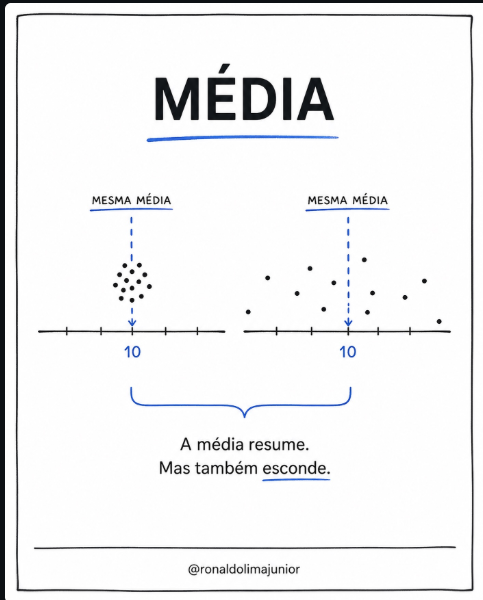

## Resultados e interpretação

1. Que diferença na experiência de espera dos usuários não aparece ao olhar apenas a média?

R:  média esconde a consistência e a previsibilidade do serviço. Olhando apenas a média, não vemos a oscilação do dia a dia (dispersão). No nosso caso, embora os postos tenham a mesma média, a experiência do usuário é completamente diferente: no Posto A o cliente tem uma espera previsível e estável (baixa variância de 2.5), enquanto no Posto B a experiência é caótica e instável, alternando entre atendimentos muito rápidos e esperas longas (alta variância de 40.0). Além disso, a média pode ser distorcida por valores extremos (outliers), mascarando a real rotina do local.

2. Por que a escolha entre `n` e `n-1` precisa considerar a finalidade da análise?

R: Porque a escolha define se estamos descrevendo um cenário fechado ou prevendo o comportamento de um grupo maior. Se a finalidade for analisar estritamente os dados coletados daquela manhã específica, usamos o divisor n (populacional), pois temos a totalidade daquele evento. Porém, se a finalidade for usar os dados daquela manhã como uma amostra para estimar o comportamento padrão de funcionamento dos postos para o resto do ano, precisamos usar o divisor n menos um (amostral). Este ajuste matemático (Correção de Bessel) eleva ligeiramente a variância para compensar o erro natural e a subestimativa que ocorrem quando não mapeamos a população inteira.

## Conferência dos critérios

Registre as evidências de conclusão e as dúvidas que restaram.